# Inference and predictions

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Running wall-to-wall inference and predicting a year the model has never seen
</div>
<!-- markdownlint-enable MD033 -->

---

You trained a model on the previous page. This page applies it to complete scenes: first the 2018 scene it was trained on, then the 2026 scene, eight years later, in which the river has changed its course. Because the true NDVI is available for 2026 as well, you can check directly whether the model transfers to a new year.

---

## 1. Motivation

A model that only works on the tiles it was trained on is not useful. Running it over complete scenes, and on imagery from a year it never saw, shows whether it learned a relationship between imagery and target that holds beyond its training data. Wall-to-wall inference also has technical details of its own (tile edges, blending, value ranges) that can leave visible traces in a continuous map if you ignore them.

---

## 2. Core idea

`geoai.predict_raster()` runs {term}`tiled inference <Tiled Inference>`: it slides a 256 × 256 window across the scene, predicts each window, and stitches the windows together. Neighbouring windows overlap, and in the overlap their predictions are blended with weights that fall off towards each window's edge, where the network has less context. `clip_range` keeps the output within the target's valid range. The result is a GeoTIFF with the same size and georeferencing as the input.

---

## 3. Workflow

### A. Load the trained model

In [1]:
import json
import logging
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
logging.getLogger("rasterio").setLevel(logging.ERROR)

import geoai
import matplotlib.pyplot as plt
import numpy as np
import rasterio

latest_file = Path("regression_runs/latest.json")
if not latest_file.exists():
    raise FileNotFoundError("Run the previous page first: it trains the model.")
latest = json.loads(latest_file.read_text())
input_bands = latest["input_bands"]
model = geoai.PixelRegressionModel.load_from_checkpoint(latest["checkpoint"], map_location="cpu")
device = geoai.get_device()
print("Experiment:", latest["experiment"], "| input bands:", input_bands, "| device:", device)

DATA_DIR = Path("data")
PRED_DIR = Path("regression_runs") / latest["experiment"] / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)
image = {year: str(DATA_DIR / f"beni_s2_{year}.tif") for year in [2018, 2026]}
reference = {year: str(DATA_DIR / f"beni_s2_{year}_ndvi.tif") for year in [2018, 2026]}

Experiment: unet-resnet34_all_mse_lr0.001_seed0 | input bands: [1, 2, 3, 4, 5, 6] | device: mps


The model is loaded from the checkpoint saved on page 5, so you do not need to train again. `geoai.get_device()` picks the fastest available processor: a CUDA GPU, an Apple GPU (`mps`) or the CPU.

### B. Predict the training year

In [2]:
start = time.time()
geoai.predict_raster(
    model=model,
    input_raster=image[2018],
    output_raster=str(PRED_DIR / "ndvi_2018.tif"),
    input_bands=input_bands,
    tile_size=256,
    overlap=64,
    batch_size=8,
    clip_range=(-1.0, 1.0),
    device=device,
)
print(f"Prediction took {time.time() - start:.0f} s")

with rasterio.open(PRED_DIR / "ndvi_2018.tif") as src:
    print("Output:", src.width, "x", src.height, "pixels,", src.dtypes[0], "| nodata:", src.nodata,
          "| same grid as input:", src.transform == rasterio.open(image[2018]).transform)

Prediction took 1 s
Output: 1500 x 1500 pixels, float32 | nodata: -9999.0 | same grid as input: True


The prediction covers the full 1,500 × 1,500 pixels, including the strips at the right and bottom edges that no training tile covered and the southern area that was held out for validation. `input_bands` must be the same bands the model was trained with; it is read from `latest.json` so the two cannot get out of step.

### C. Overlap, blending and clipping

Three parameters deserve a closer look, because each leaves measurable traces in the map.

**Overlap.** With `overlap=64`, windows start every 256 − 64 = 192 pixels and share a 64-pixel strip with their neighbours. Without overlap, each window ends where the next begins. Let us predict 2018 once more without overlap and compare the jumps between neighbouring pixels at the window boundaries with the jumps elsewhere:

In [3]:
geoai.predict_raster(model=model, input_raster=image[2018], output_raster=str(PRED_DIR / "ndvi_2018_overlap0.tif"),
                     input_bands=input_bands, tile_size=256, overlap=0, batch_size=8, clip_range=(-1.0, 1.0),
                     device=device)

def boundary_jump(path, boundaries=(256, 512, 768, 1024)):
    """Mean absolute difference across window boundaries vs. across all other columns and rows."""
    with rasterio.open(path) as src:
        pred = src.read(1)[1:-1, 1:-1]  # ignore the outermost frame (see below)
    dx = np.abs(np.diff(pred, axis=1))
    dy = np.abs(np.diff(pred, axis=0))
    b = [x - 2 for x in boundaries]  # column index of the jump after cropping one pixel
    at = np.concatenate([dx[:, b].ravel(), dy[b, :].ravel()])
    others = np.median([dx.mean(), dy.mean()])
    return at.mean(), others

for name in ["ndvi_2018_overlap0.tif", "ndvi_2018.tif"]:
    at, others = boundary_jump(PRED_DIR / name)
    print(f"{name:<24} jump at window boundaries {at:.4f}, elsewhere {others:.4f} (ratio {at / others:.1f})")

ndvi_2018_overlap0.tif   jump at window boundaries 0.0721, elsewhere 0.0176 (ratio 4.1)
ndvi_2018.tif            jump at window boundaries 0.0162, elsewhere 0.0163 (ratio 1.0)


Without overlap, the jumps at the window boundaries are clearly larger than between other neighbouring pixels: the network predicts less reliably at the edge of its window, where it lacks context on one side, and two windows disagree there. With overlap and blending, the boundaries are no longer distinguishable from the rest of the map. In a continuous map such seams show up as a faint grid; in a class map they would mostly vanish behind the class boundaries.

**The outermost frame.** The blending weights start at zero at each window edge. At the edge of the *scene*, no other window covers these pixels, so their total weight is zero, and `geoai` writes them as nodata:

In [4]:
with rasterio.open(PRED_DIR / "ndvi_2018.tif") as src:
    pred_2018 = src.read(1)
    nodata = src.nodata
frame = np.zeros(pred_2018.shape, bool)
frame[[0, -1], :] = True
frame[:, [0, -1]] = True
print(f"Nodata pixels: {np.sum(pred_2018 == nodata)}, all in the outermost frame: "
      f"{np.all((pred_2018 == nodata) <= frame)}")

Nodata pixels: 5996, all in the outermost frame: True


A one-pixel frame of nodata (−9999) around the map, with `overlap > 0`. It is flagged as nodata, so GIS software and the evaluation functions on the next page ignore it; just remember it if you compute statistics yourself.

**Clipping.** Without `clip_range`, how often would the model predict impossible values?

In [5]:
geoai.predict_raster(model=model, input_raster=image[2026], output_raster=str(PRED_DIR / "ndvi_2026_noclip.tif"),
                     input_bands=input_bands, tile_size=256, overlap=64, batch_size=8, device=device)
with rasterio.open(PRED_DIR / "ndvi_2026_noclip.tif") as src:
    raw = src.read(1)
    raw = raw[raw != src.nodata]
print(f"Unclipped 2026 prediction: {raw.min():.3f} to {raw.max():.3f}; "
      f"{np.mean((raw < -1) | (raw > 1)):.3%} of the pixels outside -1 to 1")

Unclipped 2026 prediction: -0.814 to 1.067; 0.004% of the pixels outside -1 to 1


Very rarely: the unclipped prediction ranges from −0.81 to 1.07, and only 0.004% of the pixels (about 90) are above 1. None are below −1. `clip_range` is cheap insurance: it only changes values that are impossible anyway.

### D. Predict a new year

In [6]:
path_2026 = geoai.predict_raster(
    model=model,
    input_raster=image[2026],
    output_raster=str(PRED_DIR / "ndvi_2026.tif"),
    input_bands=input_bands,
    tile_size=256,
    overlap=64,
    batch_size=8,
    clip_range=(-1.0, 1.0),
    device=device,
)
print("Saved:", path_2026)

Saved: regression_runs/unet-resnet34_all_mse_lr0.001_seed0/predictions/ndvi_2026.tif


This is the same call, applied to the 2026 scene. If the model has learned a general relationship between the bands and NDVI, rather than features specific to the 2018 scene, it should produce a plausible NDVI map for 2026 as well.

### E. Look at the 2026 prediction

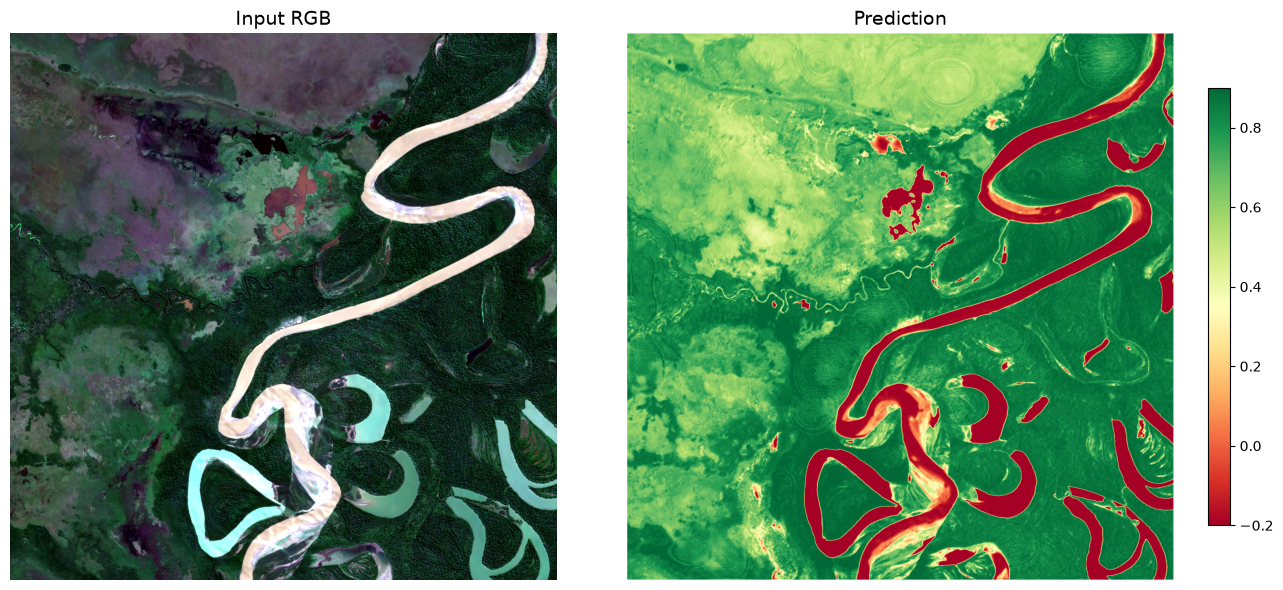

In [7]:
geoai.visualize_prediction(
    input_raster=image[2026],
    pred_raster=str(PRED_DIR / "ndvi_2026.tif"),
    rgb_bands=[3, 2, 1],
    cmap="RdYlGn",
    vmin=-0.2,
    vmax=0.9,
)

`rgb_bands=[3, 2, 1]` is needed because the bands are stored as blue, green, red: the function's default `[1, 2, 3]` would display blue as red. Visually, the predicted NDVI follows the image closely: river and oxbow lakes are red, the forest dark green, the savanna lighter.

### F. Compare with the real 2026 NDVI, and with 2018

Because the reference NDVI exists for 2026, you can compare directly. The most demanding test is **change**: does the difference between the 2026 and 2018 predictions match the real difference? This links to L10: a model that reproduces both years well should also reproduce what changed between them.

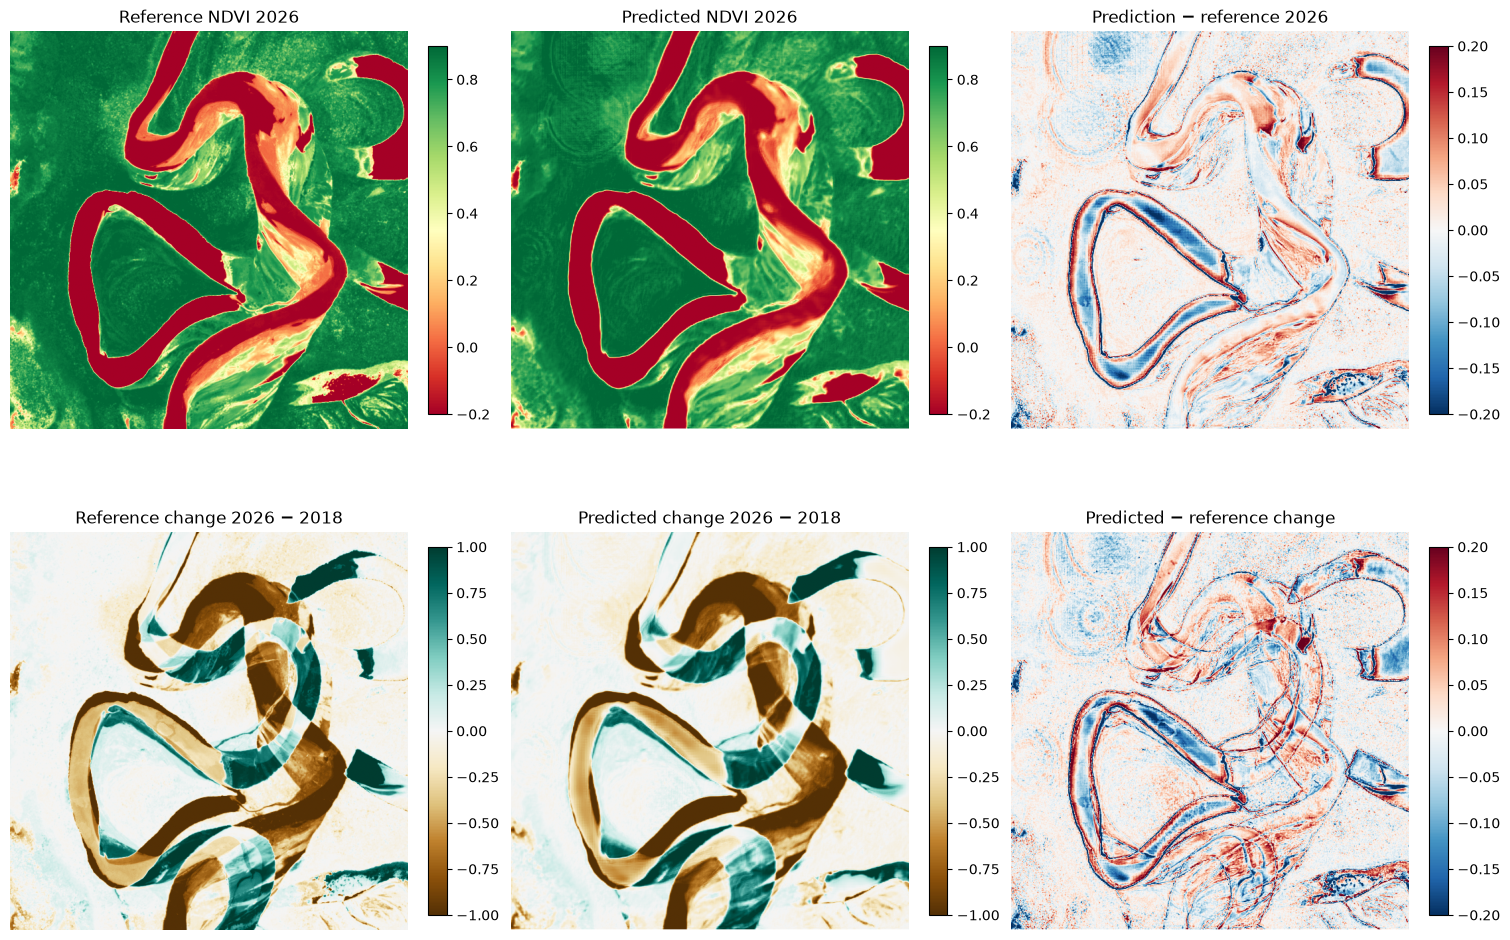

Correlation of predicted and reference change: 0.978
Where the reference NDVI hardly changed (|change| < 0.05, 59% of the scene), the predicted change is on average 0.030


In [8]:
def read(path):
    with rasterio.open(path) as src:
        arr = src.read(1).astype("float32")
        if src.nodata is not None:
            arr[arr == src.nodata] = np.nan
    return arr

pred = {y: read(PRED_DIR / f"ndvi_{y}.tif") for y in [2018, 2026]}
ref = {y: read(reference[y]) for y in [2018, 2026]}
change_pred = pred[2026] - pred[2018]
change_ref = ref[2026] - ref[2018]

zoom = (slice(900, 1500), slice(400, 1000))  # the meander cut-off in the south-west
fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
panels = [
    (ref[2026], "Reference NDVI 2026", "RdYlGn", (-0.2, 0.9)),
    (pred[2026], "Predicted NDVI 2026", "RdYlGn", (-0.2, 0.9)),
    (pred[2026] - ref[2026], "Prediction − reference 2026", "RdBu_r", (-0.2, 0.2)),
    (change_ref, "Reference change 2026 − 2018", "BrBG", (-1, 1)),
    (change_pred, "Predicted change 2026 − 2018", "BrBG", (-1, 1)),
    (change_pred - change_ref, "Predicted − reference change", "RdBu_r", (-0.2, 0.2)),
]
for ax, (arr, title, cmap, (lo, hi)) in zip(axes.ravel(), panels):
    im = ax.imshow(arr[zoom], cmap=cmap, vmin=lo, vmax=hi)
    ax.set_title(title)
    ax.set_axis_off()
    fig.colorbar(im, ax=ax, shrink=0.75)
plt.show()

valid = np.isfinite(change_pred) & np.isfinite(change_ref)
stable = valid & (np.abs(change_ref) < 0.05)
print(f"Correlation of predicted and reference change: {np.corrcoef(change_pred[valid], change_ref[valid])[0, 1]:.3f}")
print(f"Where the reference NDVI hardly changed (|change| < 0.05, {stable.sum() / valid.sum():.0%} of the scene), "
      f"the predicted change is on average {np.abs(change_pred[stable]).mean():.3f}")

The zoom shows the south-west of the scene, where the river cut through a meander between the two dates. The new channel appears in the 2026 prediction, and the abandoned one turns green: the model does not remember the 2018 river, it reads each image anew. The right column shows the errors. Predicted and reference change agree closely (correlation 0.98). Where the NDVI hardly changed, about 60% of the scene, the predicted change is still 0.03 on average: small, but not zero, because the errors of the two predictions do not cancel. If you thresholded the predicted change at, say, 0.05, you would find "change" in many stable pixels. Most disagreements trace the river banks and the edges of the new oxbow lake.

```{admonition} Temporal transfer is easy here, and harder in general
:class: important
The relationship between the bands and NDVI is a fixed formula, so it cannot change between 2018 and 2026; only the landscape changed. For a measured target such as biomass, the relationship itself can shift between dates: a different season, sensor calibration, atmospheric conditions or a different stage of the vegetation. Always test a model on a date with reference data before relying on its predictions for dates without.
```

---

## 4. Python reactivation

`pred = {y: read(...) for y in [2018, 2026]}` is a dictionary comprehension: it builds a dictionary with the years as keys, the same idea as a list comprehension, with `key: value` pairs. Storing related arrays under meaningful keys (`pred[2026]`, `ref[2018]`) keeps the code readable and avoids variables such as `pred1`, `pred2`.

The `read()` helper converts the nodata value to `np.nan`, so that later calculations (differences, correlations) can exclude these pixels with `np.isfinite()`.

---

## 5. Common pitfalls

- **Using different bands, band order or scaling at prediction than at training.** The model does not check; it simply produces wrong values. Keep `input_bands` and the scaling identical, ideally read from the same configuration.
- **Setting `overlap=0`.** Window boundaries then appear as a faint grid in a continuous map.
- **Forgetting the nodata frame and value.** Statistics computed on the raw array include −9999 values unless you mask them.
- **Skipping `clip_range`.** Rare, but impossible values otherwise end up in your map.
- **Assuming temporal transfer always works.** It worked here because the relationship cannot change. For measured targets, test on a date with reference data first.

---

## 6. Mini task

1. Predict 2026 once with `tile_size=128` and `overlap=32`. Does the result change? (Hint: compare it with `ndvi_2026.tif` using the `read()` helper and the mean absolute difference.)
2. In the change maps of step F, where do predicted and reference change disagree most? Suggest a reason.

:::{dropdown} Sample solution
:class: note

1. The predictions change slightly: by about 0.01 NDVI on average, and by up to about 0.07 for the 1% of pixels that change most. Smaller windows give the network less context per prediction and create more window boundaries. With a well-trained model and overlap, the effect is small; with 128-pixel windows and no overlap, the seams would be more visible.

2. The largest disagreements lie along the river banks, sand bars and the edges of the oxbow lakes, where land and water meet within a 10 m pixel. These mixed pixels have intermediate NDVI values that change strongly with small shifts of the water line, and the model's errors are largest there in both years (page 7 quantifies this). Errors of both years add up in a difference, so change maps are always noisier than the maps they are computed from, the same lesson as for post-classification comparison in L10.
:::

---

## 7. Key takeaways

- `predict_raster()` runs wall-to-wall inference with overlapping windows and blending; overlap removes visible seams, at the cost of computing some pixels twice.
- With `overlap > 0`, `geoai` 0.43 leaves a one-pixel nodata frame around the output; mask the nodata value when computing statistics.
- `clip_range` enforces the target's valid range on the predictions, the inference-time counterpart to `target_min`/`target_max`.
- Bands, band order and scaling at prediction must match training exactly.
- With reference data for a second year, you can test temporal transfer directly, including whether predicted *change* matches real change.